# African wildlife detection — YOLO11n

CSCI1409 Deep Learning · Bonus project · KBTU

We train a detector to find four animals in photos:
**buffalo, elephant, rhino, zebra**.

The notebook runs from top to bottom: it downloads the data, checks the labels,
trains two models, compares them, tests the better one, and looks at the errors.

**Runtime → Change runtime type → T4 GPU.**

After every part there is a short **"What we got"** cell. It prints the result
in words, using the numbers from the cell above, so the text always matches
this run.

## 1. Setup

In [9]:
!pip install -q ultralytics==8.4.215

In [10]:
import os, glob, shutil, time, json, csv, collections, statistics, random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches        # to draw the boxes
from PIL import Image
import torch, ultralytics
from ultralytics import YOLO

SEED = 0                                    # same seed -> same result
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

print("torch      :", torch.__version__)
print("ultralytics:", ultralytics.__version__)
print("GPU        :", torch.cuda.is_available())

torch      : 2.14.1+cu130
ultralytics: 8.4.215
GPU        : True


### Settings

Everything is here. The two runs share all of it except `MOSAIC`.

In [11]:
MODEL   = "yolo11n.pt"    # small model, pretrained on COCO
EPOCHS  = 50
BATCH   = 16
IMGSZ   = 640
LR0     = 0.01            # SGD learning rate
OPT     = "SGD"           # write the name: with "auto" ultralytics ignores LR0

MOSAIC_1 = 1.0            # run 1: mosaic on (the ultralytics default)
MOSAIC_2 = 0.0            # run 2: mosaic off - the only change

CLASSES = ["buffalo", "elephant", "rhino", "zebra"]
COLORS  = ["#e8453c", "#2d7dd2", "#f5a623", "#30a46c"]

CONF = 0.001              # confidence for the metrics
IOU  = 0.6                # IoU for the metrics
SHOW_CONF = 0.25          # confidence for pictures and error analysis

## 2. Data

**African Wildlife** by Ultralytics.
Documentation: https://docs.ultralytics.com/datasets/detect/african-wildlife/
Licence: **AGPL-3.0** (the same licence as ultralytics itself).

1504 photos, 4 classes, already in **YOLO format**, and the author already
gives train / val / test folders. So we do not convert anything and we do not
invent a split.

## 3. Read the labels

One `.txt` per photo. Every line is one animal:
`class  centre_x  centre_y  width  height`, all divided by the image size,
so every number is between 0 and 1.

In [12]:
ROOT = "."

if not os.path.exists(ROOT):
    !wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/african-wildlife.zip
    !unzip -q african-wildlife.zip

for s in ["train", "val", "test"]:
    print(s, len(os.listdir(ROOT + "/images/" + s)), "images")
print()
print(open(ROOT + "/LICENSE.txt").readline().strip())

train 1052 images
val 225 images
test 227 images

GNU AFFERO GENERAL PUBLIC LICENSE


In [13]:
SPLITS = ["train", "val", "test"]
images = {s: sorted(glob.glob(ROOT + "/images/" + s + "/*")) for s in SPLITS}

def label_of(image_path):
    # photos/images/train/x.jpg -> photos/labels/train/x.txt
    return image_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"

boxes = {}          # photo -> list of (class id, cx, cy, w, h)
no_file = []        # photos with no label file
for s in SPLITS:
    for p in images[s]:
        path = label_of(p)
        if not os.path.exists(path):
            no_file.append(p)
            continue
        boxes[p] = [tuple(map(float, line.split())) for line in open(path) if line.strip()]

print("photos with labels:", len(boxes))
print("photos with no label file:", len(no_file))
print()
print(open(label_of(images["train"][0])).read())

photos with labels: 1504
photos with no label file: 0

0 0.410000 0.408750 0.400000 0.382500


### 3.1 How many photos and animals in each split

In [14]:
print(f"{'split':8}{'photos':>8}{'animals':>9}   " + "".join(f"{c:>10}" for c in CLASSES))
counts = {}
for s in SPLITS:
    c = collections.Counter()
    for p in images[s]:
        for k, x, y, w, h in boxes.get(p, []):
            c[CLASSES[int(k)]] += 1
    counts[s] = c
    print(f"{s:8}{len(images[s]):>8}{sum(c.values()):>9}   "
          + "".join(f"{c[name]:>10}" for name in CLASSES))

total = collections.Counter()
for s in SPLITS:
    total += counts[s]
print(f"{'total':8}{len(boxes):>8}{sum(total.values()):>9}   "
      + "".join(f"{total[name]:>10}" for name in CLASSES))

# does one photo appear in two splits?
names = {s: {os.path.basename(p) for p in images[s]} for s in SPLITS}
shared = (len(names["train"] & names["val"]) + len(names["train"] & names["test"])
          + len(names["val"] & names["test"]))
print("file names in two splits:", shared)

split     photos  animals      buffalo  elephant     rhino     zebra
train       1052     1931          399       558       399       575
val          225      379           89        91        85       114
test         227      375           66        99        75       135
total       1504     2685          554       748       559       824
file names in two splits: 0


**What we got**

In [15]:
biggest  = max(CLASSES, key=lambda c: total[c])
smallest = min(CLASSES, key=lambda c: total[c])
print("We have", len(boxes), "photos and", sum(total.values()), "animals.")
print(f"The classes are well balanced: {smallest} {total[smallest]}, "
      f"{biggest} {total[biggest]}.")
print("Balance matters: with 10x difference a model can ignore a rare class")
print("and still look good. Here every class really has to work.")
if shared == 0:
    print("No file name is in two splits.")

We have 1504 photos and 2685 animals.
The classes are well balanced: buffalo 554, zebra 824.
Balance matters: with 10x difference a model can ignore a rare class
and still look good. Here every class really has to work.
No file name is in two splits.


## 4. How big are the animals in the photo

The photos have different sizes, so we measure the box as a **part of the
image**, not in pixels. We use the square root of the area: it is the side of
a square of the same size.

In [16]:
side = collections.defaultdict(list)
per_photo = []
for p in boxes:
    per_photo.append(len(boxes[p]))
    for k, x, y, w, h in boxes[p]:
        side[CLASSES[int(k)]].append((w * h) ** 0.5)     # part of the image

print(f"{'class':10}{'animals':>9}{'median box side':>18}")
for c in CLASSES:
    print(f"{c:10}{len(side[c]):>9}{statistics.median(side[c]) * 100:>17.0f}%")

print()
print("animals per photo: min", min(per_photo),
      " median", statistics.median(per_photo), " max", max(per_photo))

class       animals   median box side
buffalo         554               56%
elephant        748               42%
rhino           559               55%
zebra           824               38%

animals per photo: min 1  median 1.0  max 25


**What we got**

In [17]:
median_side = statistics.median([s for c in CLASSES for s in side[c]]) * 100
crowded = sum(1 for n in per_photo if n >= 5)
print("A typical animal fills about", round(median_side), "% of the photo.")
print("That is very big: the object is almost the whole picture.")
print("Most photos have one animal; only", crowded, "photos have 5 or more.")
print("So this task is mostly 'find one big object', not 'find many small ones'.")
print("We use this fact to choose the experiment in part 9.")

A typical animal fills about 46 % of the photo.
That is very big: the object is almost the whole picture.
Most photos have one animal; only 62 photos have 5 or more.
So this task is mostly 'find one big object', not 'find many small ones'.
We use this fact to choose the experiment in part 9.


## 5. Problems in the labels

We check what we can count: photos with no animal, and boxes that go outside
the image (a wrong box can make the loss strange).

In [18]:
empty = [p for p in boxes if len(boxes[p]) == 0]

outside = 0
for p in boxes:
    for k, x, y, w, h in boxes[p]:
        # the box must stay inside 0..1; we allow 1% for rounding
        if x - w / 2 < -0.01 or y - h / 2 < -0.01 or x + w / 2 > 1.01 or y + h / 2 > 1.01:
            outside += 1

big = sum(1 for p in boxes for k, x, y, w, h in boxes[p] if w * h > 0.9)

print("photos with no animal :", len(empty))
print("boxes outside the image:", outside)
print("boxes covering >90% of the photo:", big)

photos with no animal : 0
boxes outside the image: 0
boxes covering >90% of the photo: 17


**What we got**

In [19]:
if len(no_file) == 0 and len(empty) == 0 and outside == 0:
    print("The labels are clean: every photo has a label, nothing is empty,")
    print("and no box goes outside the image.")
else:
    print("Problems found:", len(no_file), "photos with no label,",
          len(empty), "empty,", outside, "boxes outside the image.")
print(big, "boxes cover more than 90% of the photo.")
print("These are close-up photos. They are easy for the model,")
print("but they teach it very little about animals that are far away.")

The labels are clean: every photo has a label, nothing is empty,
and no box goes outside the image.
17 boxes cover more than 90% of the photo.
These are close-up photos. They are easy for the model,
but they teach it very little about animals that are far away.


## 6. The same photo in two splits

File names are all different, but the **same photo** can be saved twice under
two names. If a photo is in train and also in test, we test on something the
model has already learned, and the score is too good.

We make a small hash of every photo and compare all pairs.

In [20]:
def dhash(path):
    # 9x8 grey thumbnail -> 64 True/False values
    a = np.asarray(Image.open(path).convert("L").resize((9, 8)), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

all_photos = [p for s in SPLITS for p in images[s]]
where = {p: s for s in SPLITS for p in images[s]}
H = np.array([dhash(p) for p in all_photos])

pairs = []
for i in range(len(all_photos)):
    # compare photo i with every photo after it, all at once
    distance = (H[i + 1:] != H[i]).sum(1)          # how many of the 64 bits differ
    for k, d in enumerate(distance):
        if d <= 8:                                 # 8 of 64 -> the same photo
            pairs.append((int(d), all_photos[i], all_photos[i + 1 + k]))
pairs.sort()

crossing = [(d, a, b) for d, a, b in pairs if where[a] != where[b]]
kinds = collections.Counter(tuple(sorted((where[a], where[b]))) for d, a, b in pairs)

print("similar pairs:", len(pairs))
print("by split pair:", dict(kinds))
print("pairs that cross a split:", len(crossing))
print()
for d, a, b in crossing[:8]:
    print(f"   distance {d}: {os.path.basename(a)} ({where[a]})"
          f"  <->  {os.path.basename(b)} ({where[b]})")

similar pairs: 75
by split pair: {('test', 'test'): 3, ('train', 'train'): 33, ('train', 'val'): 11, ('test', 'train'): 23, ('val', 'val'): 2, ('test', 'val'): 3}
pairs that cross a split: 37

   distance 0: 1 (124).jpg (train)  <->  1 (122).jpg (val)
   distance 0: 1 (151).jpg (train)  <->  1 (103).jpg (test)
   distance 0: 1 (229).jpg (train)  <->  1 (223).jpg (val)
   distance 0: 1 (237).jpg (train)  <->  1 (365).jpg (test)
   distance 0: 1 (314).jpg (train)  <->  1 (183).jpg (test)
   distance 0: 1 (322).jpg (train)  <->  1 (128).jpg (test)
   distance 0: 1 (371).jpg (train)  <->  1 (171).jpg (test)
   distance 0: 1 (70).jpg (train)  <->  1 (74).jpg (test)


pixel correlation: 1.0
the files are byte-for-byte equal: True


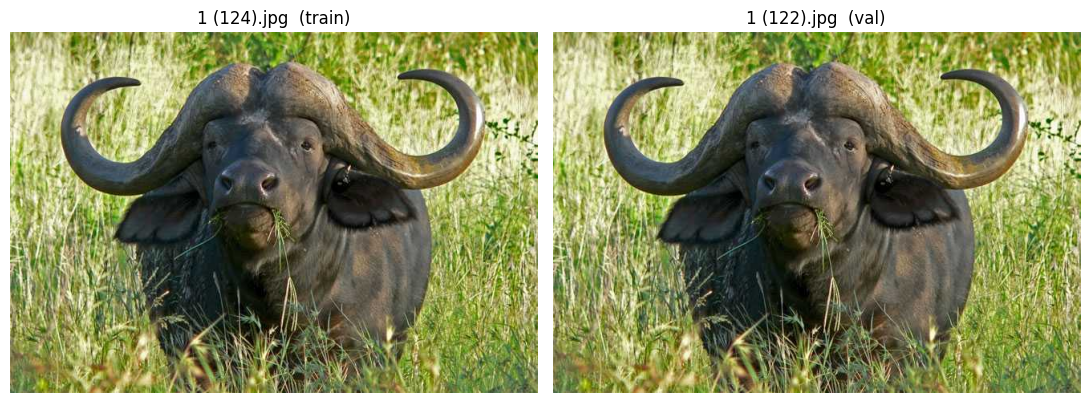

In [21]:
# look at one pair, so we do not trust the hash blindly
if crossing:
    d, a, b = crossing[0]
    ia = np.asarray(Image.open(a).convert("L").resize((128, 128)), float)
    ib = np.asarray(Image.open(b).convert("L").resize((128, 128)), float)
    print("pixel correlation:", round(float(np.corrcoef(ia.ravel(), ib.ravel())[0, 1]), 3))
    print("the files are byte-for-byte equal:",
          open(a, "rb").read() == open(b, "rb").read())

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].imshow(Image.open(a)); ax[0].set_title(os.path.basename(a) + "  (" + where[a] + ")")
    ax[1].imshow(Image.open(b)); ax[1].set_title(os.path.basename(b) + "  (" + where[b] + ")")
    for x in ax:
        x.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("no photo is repeated in two splits")

**What we got**

In [22]:
same_file = sum(1 for d, a, b in crossing
                if open(a, "rb").read() == open(b, "rb").read())
print(len(crossing), "pairs cross a split, and", same_file,
      "of them are exactly the same file.")
print("So the author copied some photos into two folders.")
print("The pairs inside one split are fine - the task only asks us")
print("to keep copies on the same side. The crossing ones we must fix.")

37 pairs cross a split, and 21 of them are exactly the same file.
So the author copied some photos into two folders.
The pairs inside one split are fine - the task only asks us
to keep copies on the same side. The crossing ones we must fix.


### 6.1 Fix it

We do not move photos into train, because that would make the test set
smaller. We **remove the training copy** instead: then the test photo stays,
and the model has never seen it.

The rule has no random part:
*if the same photo is in two splits, delete the copy that is in train;
if neither copy is in train, delete the one in test.*

In [23]:
drop = set()
for d, a, b in crossing:
    pair = [a, b]
    in_train = [p for p in pair if where[p] == "train"]
    in_test  = [p for p in pair if where[p] == "test"]
    if in_train:
        drop.add(in_train[0])
    elif in_test:
        drop.add(in_test[0])

keep = {s: [p for p in images[s] if p not in drop] for s in SPLITS}

print("photos removed:", len(drop),
      dict(collections.Counter(where[p] for p in drop)))
print("before:", {s: len(images[s]) for s in SPLITS})
print("after :", {s: len(keep[s]) for s in SPLITS})

# check that no crossing pair is left
left = [1 for d, a, b in crossing if a not in drop and b not in drop]
print("crossing pairs left:", len(left))

photos removed: 36 {'train': 34, 'test': 2}
before: {'train': 1052, 'val': 225, 'test': 227}
after : {'train': 1018, 'val': 225, 'test': 225}
crossing pairs left: 0


### 6.2 Write our data.yaml

We do not copy 1500 files. We write a text file with the list of photos we
keep, and YOLO reads the list. The label for each photo is found by replacing
`images` with `labels`, which is how the folders are built.

In [24]:
os.makedirs("lists", exist_ok=True)
for s in SPLITS:
    open("lists/" + s + ".txt", "w").write(
        "\n".join(os.path.abspath(p) for p in keep[s]))

DATA = os.path.abspath("data.yaml")
open(DATA, "w").write(
    "path: " + os.path.abspath(ROOT) + "\n"
    "train: " + os.path.abspath("lists/train.txt") + "\n"
    "val: "   + os.path.abspath("lists/val.txt")   + "\n"
    "test: "  + os.path.abspath("lists/test.txt")  + "\n"
    "nc: 4\nnames: ['buffalo', 'elephant', 'rhino', 'zebra']\n")

print(open(DATA).read())

path: /content
train: /content/lists/train.txt
val: /content/lists/val.txt
test: /content/lists/test.txt
nc: 4
names: ['buffalo', 'elephant', 'rhino', 'zebra']



## 7. Six training photos with their boxes

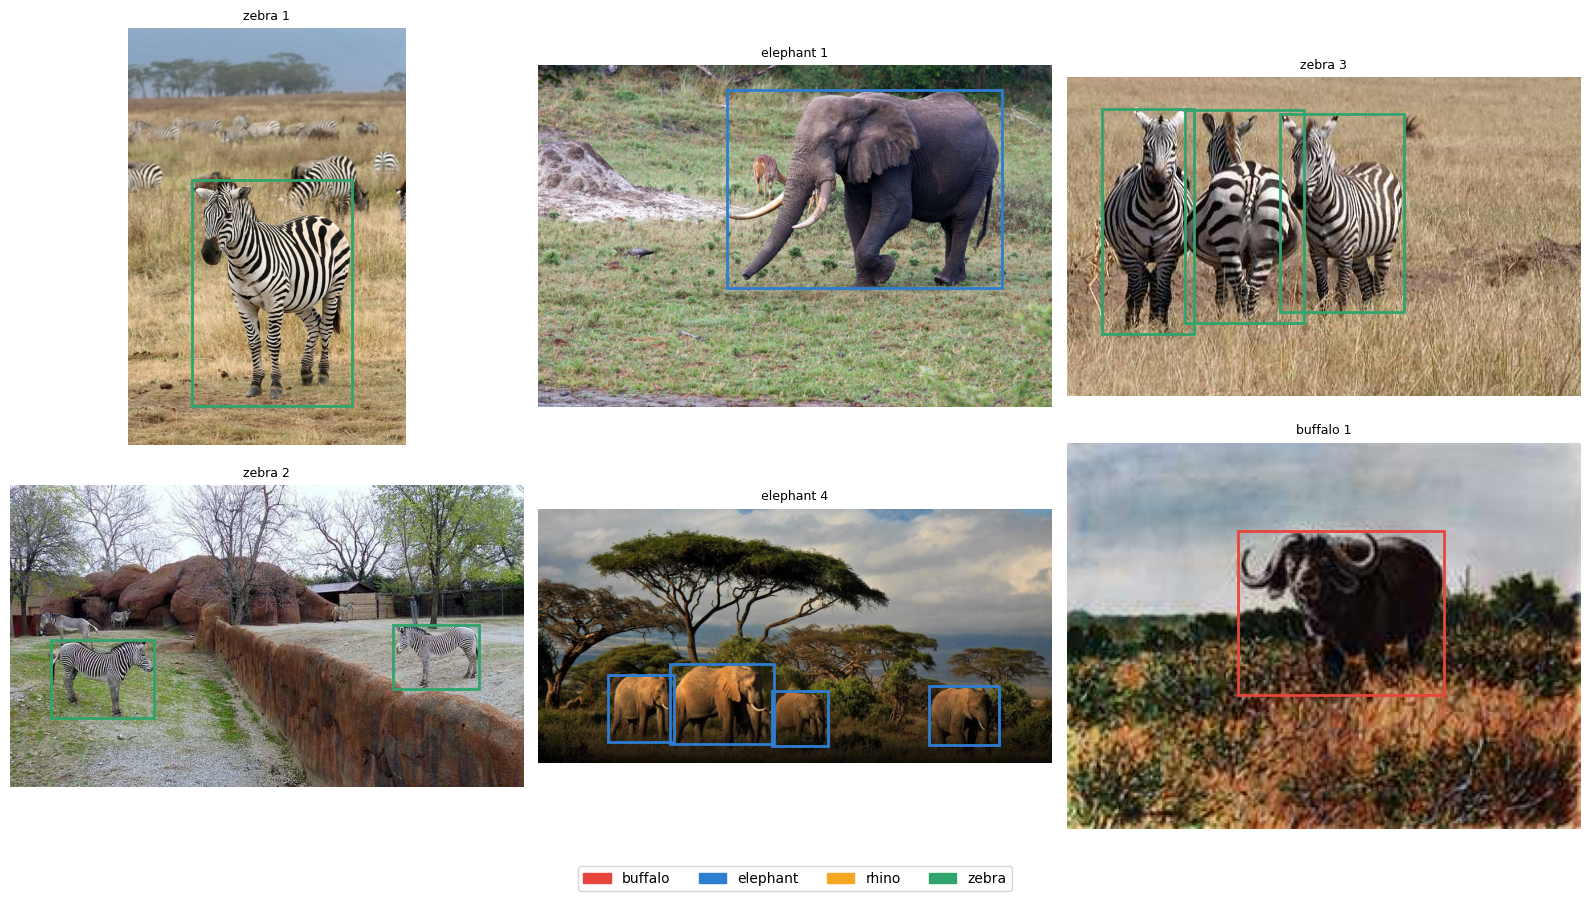

In [25]:
def draw_boxes(ax, image_path, title=True):
    # draws the true boxes of one photo on one subplot
    img = Image.open(image_path)
    W, H = img.size
    ax.imshow(img); ax.axis("off")
    c = collections.Counter()
    for k, x, y, w, h in boxes[image_path]:
        k = int(k)
        x, y, w, h = x * W, y * H, w * W, h * H          # back to pixels
        # Rectangle wants the top-left corner, we have the centre
        ax.add_patch(patches.Rectangle((x - w / 2, y - h / 2), w, h,
                                       fill=False, color=COLORS[k], lw=2))
        c[CLASSES[k]] += 1
    if title:
        ax.set_title(", ".join(f"{n} {c[n]}" for n in CLASSES if c[n]), fontsize=9)
    return c

random.seed(SEED)
examples = random.sample(keep["train"], 6)          # 6 random training photos

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, p in zip(axes.ravel(), examples):
    draw_boxes(ax, p)
fig.legend(handles=[patches.Patch(color=COLORS[i], label=CLASSES[i]) for i in range(4)],
           loc="lower center", ncol=4)
plt.tight_layout(rect=[0, 0.04, 1, 1])
os.makedirs("results", exist_ok=True)
fig.savefig("results/ground_truth_examples.png", dpi=110, bbox_inches="tight")
plt.show()

**What we got**

The boxes are tight around the animals, and one animal usually fills a large
part of the photo. The photos are normal photographs, so the background, the
light and the distance change a lot. That, and not the size of the object, is
the difficult part of this dataset.

**One thing to notice in the labels.** When there is a herd far behind the main
animal, the animals in the background often have **no box**. The labels mark
the animal the photo is about, not every animal in the picture. This is not a
mistake we can fix, but it changes the score: if the model finds a zebra in the
background, the metric counts it as a false positive. We measure how often this
happens in part 16, under *"nothing is there"*.

## 8. Our hypothesis (written before training)

**Run 1:** YOLO11n with the normal settings. Mosaic augmentation is **on**
(`mosaic = 1.0`), which is the ultralytics default.
**Run 2:** the same, but mosaic is **off** (`mosaic = 0.0`). Nothing else changes.

**What mosaic does:** it glues 4 photos into one picture, so every object
becomes about 2 times smaller. It is made for pictures with many small objects,
because it shows the model more objects in one step.

**We think:** mosaic will help very little here, and it may even make the
result worse. Part 4 showed that a typical animal fills about half of the
photo and that most photos have only one animal. Mosaic shrinks these big
animals and fills the picture with cut pieces that look nothing like a normal
photo, which is not what the model will see at test time.

**We also think** run 2 will be a little faster, because mosaic has to build
every training picture from four photos.

**This would show that we are wrong:** mAP@0.50 clearly goes down without
mosaic. That would mean the model needs the extra variety more than it needs
pictures that look realistic.

We also set `close_mosaic = 0` in **both** runs. By default ultralytics turns
mosaic off for the last 10 epochs, and then the two runs would differ in two
things instead of one.

## 9. Run 1 — mosaic on

In [26]:
start = time.time()
torch.manual_seed(SEED)                 # same start for both runs

model1 = YOLO(MODEL)
model1.train(data=DATA, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
             lr0=LR0, optimizer=OPT, seed=SEED,
             mosaic=MOSAIC_1,           # <-- the setting we study
             close_mosaic=0,            # do not turn mosaic off at the end
             project="runs", name="run1_mosaic_on", exist_ok=True,
             plots=True,                # save the learning curves
             verbose=False)             # short log

time1 = time.time() - start
DIR1 = str(model1.trainer.save_dir)     # ask the trainer where it really saved
BEST1 = DIR1 + "/weights/best.pt"       # best.pt = best epoch on validation
print("time   :", round(time1 / 60, 1), "min")
print("weights:", BEST1)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=run1_mosaic_on, nbs=64, nms=None, opset=None, optimize=False, optimizer=

## 10. Run 2 — mosaic off

In [27]:
start = time.time()
torch.manual_seed(SEED)

model2 = YOLO(MODEL)                    # the same pretrained weights as run 1
model2.train(data=DATA, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
             lr0=LR0, optimizer=OPT, seed=SEED,
             mosaic=MOSAIC_2,           # <-- the only difference
             close_mosaic=0,
             project="runs", name="run2_mosaic_off", exist_ok=True,
             plots=True, verbose=False)

time2 = time.time() - start
DIR2 = str(model2.trainer.save_dir)
BEST2 = DIR2 + "/weights/best.pt"
print("time   :", round(time2 / 60, 1), "min")
print("weights:", BEST2)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=run2_mosaic_off, nbs=64, nms=None, opset=None, optimize=False, optimizer

## 11. Save the logs and the learning curves

`runs/` is too big for GitHub, so we copy the small files into `results/`.

In [28]:
RUNS = {"run1_mosaic_on": DIR1, "run2_mosaic_off": DIR2}

for name in RUNS:
    out = "results/" + name
    os.makedirs(out, exist_ok=True)
    for fn in ["args.yaml", "results.csv", "results.png",
               "confusion_matrix_normalized.png", "BoxPR_curve.png"]:
        if os.path.exists(RUNS[name] + "/" + fn):
            shutil.copy(RUNS[name] + "/" + fn, out + "/" + fn)
    print(name, "->", sorted(os.listdir(out)))

run1_mosaic_on -> ['BoxPR_curve.png', 'args.yaml', 'confusion_matrix_normalized.png', 'results.csv', 'results.png']
run2_mosaic_off -> ['BoxPR_curve.png', 'args.yaml', 'confusion_matrix_normalized.png', 'results.csv', 'results.png']


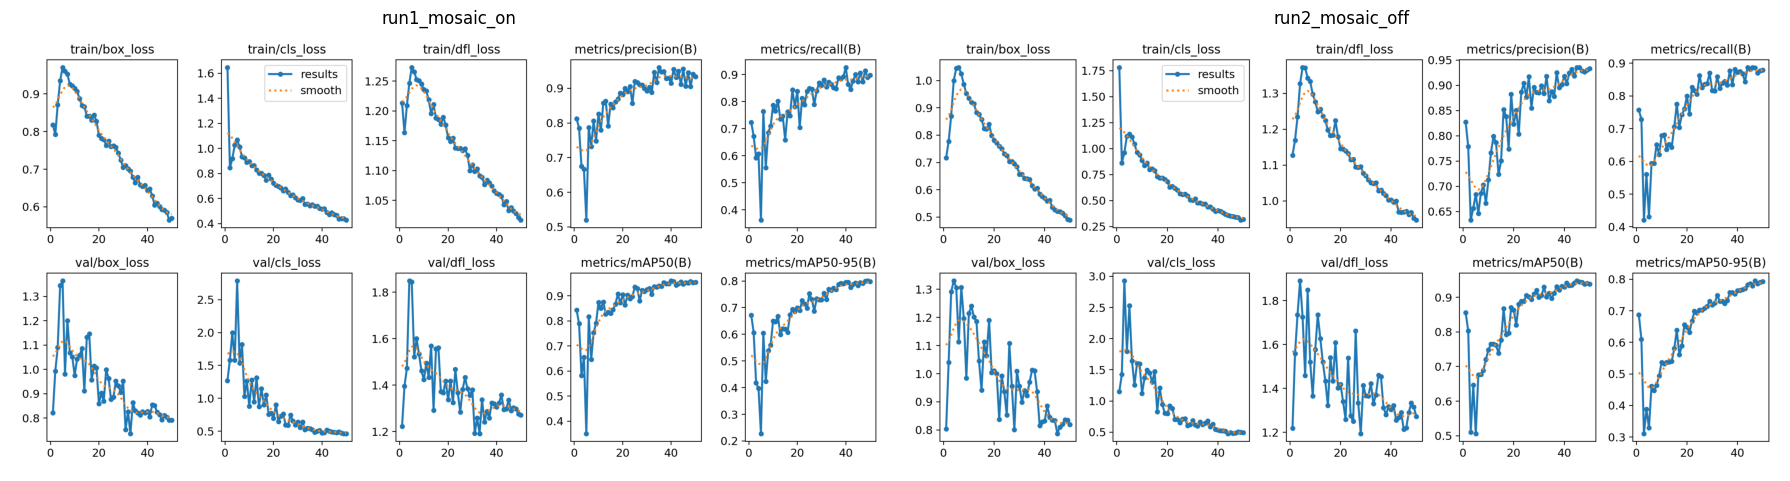

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, name in zip(axes, RUNS):
    ax.imshow(Image.open("results/" + name + "/results.png"))
    ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()

**What we got**

In [30]:
def value(row, key):                      # the column names have spaces
    return float([v for k, v in row.items() if key in k][0])

for name in RUNS:
    rows = list(csv.DictReader(open("results/" + name + "/results.csv")))
    loss = [value(r, "train/box_loss") for r in rows]
    maps = [value(r, "mAP50(B)") for r in rows]
    best_epoch = maps.index(max(maps)) + 1

    print(name + ":", len(rows), "epochs")
    print("   box loss:", round(loss[0], 2), "->", round(loss[-1], 2))
    print("   best validation mAP50:", round(max(maps), 3), "at epoch", best_epoch)

    if len(rows) < 2:
        print("   Only one epoch, so we cannot see a trend.")
    elif loss[-1] < loss[0] and max(maps) > 0:
        print("   The loss went down and the score is not zero, so training worked.")
    else:
        print("   WARNING: the loss did not go down. Check the learning rate.")

    if len(rows) >= 10 and best_epoch < len(rows) - 10:
        print("   The best epoch is early, so the last epochs did not help.")
    elif len(rows) >= 10:
        print("   The best epoch is near the end, so the model was still improving.")

run1_mosaic_on: 50 epochs
   box loss: 0.82 -> 0.57
   best validation mAP50: 0.96 at epoch 40
   The loss went down and the score is not zero, so training worked.
   The best epoch is near the end, so the model was still improving.
run2_mosaic_off: 50 epochs
   box loss: 0.72 -> 0.49
   best validation mAP50: 0.948 at epoch 45
   The loss went down and the score is not zero, so training worked.
   The best epoch is near the end, so the model was still improving.


## 12. Compare the two runs on validation

The test set is still closed. We choose the better run here, with validation
only.

In [31]:
def evaluate(weights, split):
    # runs the model on one split and returns the metrics as a dict
    m = YOLO(weights)
    r = m.val(data=DATA, split=split, imgsz=IMGSZ, conf=CONF, iou=IOU,
              verbose=False, plots=False)
    out = {"precision": r.box.mp,            # mp = mean precision
           "recall": r.box.mr,               # mr = mean recall
           "mAP50": r.box.map50, "mAP50-95": r.box.map}
    for i, c in enumerate(CLASSES):          # the same numbers per class
        out[c + " precision"] = r.box.p[i]
        out[c + " recall"]    = r.box.r[i]
        out[c + " mAP50"]     = r.box.ap50[i]
    return out

val1 = evaluate(BEST1, "val")
val2 = evaluate(BEST2, "val")

print(f"{'':22}{'mosaic on':>12}{'mosaic off':>12}")
for k in ["precision", "recall", "mAP50", "mAP50-95"]:
    print(f"{k:22}{val1[k]:>12.3f}{val2[k]:>12.3f}")
print()
for c in CLASSES:
    key = c + " mAP50"
    print(f"{key:22}{val1[key]:>12.3f}{val2[key]:>12.3f}")
print()
print(f"{'training time, min':22}{time1 / 60:>12.1f}{time2 / 60:>12.1f}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1531.2±1352.4 MB/s, size: 59.8 KB)
val: Scanning /content/labels/val.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 94.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 7.3it/s 2.1s
                   all        225        379      0.943      0.891      0.954      0.794
Speed: 0.8ms preprocess, 3.5ms inference, 0.0ms loss, 1.4ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2010.3±1034.6 MB/s, size: 84.3 KB)
val: Scanning /content/labels/val.cache... 225 images, 0 backgrounds, 0 corr

**What we got — is our hypothesis true?**

In [32]:
d_map = val2["mAP50"] - val1["mAP50"]
print("mAP50 without mosaic minus with mosaic:", round(d_map, 3))
print("time saved:", round((time1 - time2) / 60, 1), "min")
print()
for c in CLASSES:
    print(f"   {c:10} {val2[c + ' mAP50'] - val1[c + ' mAP50']:+.3f}")
print()

if d_map > 0.005:
    print("Turning mosaic OFF made the model better, so our hypothesis is TRUE.")
    print("Reason: the animals are big and there is one per photo,")
    print("so mosaic only shrinks them and shows unrealistic pictures.")
elif d_map > -0.005:
    print("The two runs are almost the same, so mosaic changes almost nothing here.")
    print("Our hypothesis said 'mosaic helps very little', and that is what we see.")
    print("The useful part is the time: mosaic costs extra minutes for no gain.")
else:
    print("Turning mosaic off made the model WORSE, so our hypothesis is FALSE.")
    print("Then the extra variety from mosaic is worth more than realistic pictures,")
    print("even with big objects. With only ~1000 training photos the model")
    print("probably needs that variety to avoid learning the backgrounds.")

mAP50 without mosaic minus with mosaic: -0.011
time saved: 0.8 min

   buffalo    -0.006
   elephant   -0.012
   rhino      +0.001
   zebra      -0.027

Turning mosaic off made the model WORSE, so our hypothesis is FALSE.
Then the extra variety from mosaic is worth more than realistic pictures,
even with big objects. With only ~1000 training photos the model
probably needs that variety to avoid learning the backgrounds.


## 13. Test — we use it only once

We take the run with the better validation mAP50 and run it on the test set.
We do not change anything after this.

In [33]:
if val2["mAP50"] >= val1["mAP50"]:       # the choice uses validation only
    FINAL_NAME, FINAL_WEIGHTS = "run2_mosaic_off", BEST2
else:
    FINAL_NAME, FINAL_WEIGHTS = "run1_mosaic_on", BEST1

val_final = val2 if FINAL_NAME == "run2_mosaic_off" else val1
print("chosen by validation:", FINAL_NAME)

test = evaluate(FINAL_WEIGHTS, "test")   # first and last time we touch the test set

print()
print("TEST   conf =", CONF, " IoU =", IOU)
for k in ["precision", "recall", "mAP50", "mAP50-95"]:
    print(f"   {k:12}{test[k]:>8.3f}")
print()
for c in CLASSES:
    print(f"   {c:10} precision {test[c + ' precision']:.3f}"
          f"   recall {test[c + ' recall']:.3f}   mAP50 {test[c + ' mAP50']:.3f}")

chosen by validation: run1_mosaic_on
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1127.7±863.0 MB/s, size: 33.3 KB)
val: Scanning /content/labels/test... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 2.0Kit/s 0.1s
val: New cache created: /content/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 7.2it/s 2.1s
                   all        225        373      0.967      0.948      0.976      0.839
Speed: 0.9ms preprocess, 2.9ms inference, 0.0ms loss, 1.7ms postprocess per image

TEST   conf = 0.001  IoU = 0.6
   precision      0.967
   recall         0.948
   mAP50          0.976
   mAP50-95       0.839

   buffalo    precision 0.974   recall 0.955   mAP50 0.959
   elephant   precision 0.955   recall 0.939   mAP50 0.981


**What the metrics mean**

* **Precision** — the model said "this is an animal": how often was it right?
* **Recall** — of all the real animals, how many did the model find?
* **mAP@0.50** — the area under the precision-recall curve, the average of the
  4 classes. A box is correct if it covers at least 50% of the true box
  (IoU ≥ 0.50).
* **mAP@0.50-0.95** — the same, but averaged over many IoU levels. It also asks
  the box to be exact, not only in the right place.

**What we got**

In [34]:
gap = val_final["mAP50"] - test["mAP50"]
print("validation mAP50:", round(val_final["mAP50"], 3))
print("test mAP50      :", round(test["mAP50"], 3))
print("difference      :", round(gap, 3))
if abs(gap) < 0.05:
    print("Test and validation agree, so the model works on new photos too.")
else:
    print("Test and validation do not agree. The test set has only",
          len(keep["test"]), "photos,")
    print("so a part of this difference is simply luck.")
print()

best  = max(CLASSES, key=lambda c: test[c + " mAP50"])
worst = min(CLASSES, key=lambda c: test[c + " mAP50"])
print("Best class :", best, round(test[best + " mAP50"], 3))
print("Worst class:", worst, round(test[worst + " mAP50"], 3))
print("gap between them:", round(test[best + " mAP50"] - test[worst + " mAP50"], 3))
print()
if test[worst + " recall"] < test[worst + " precision"] - 0.2:
    print(worst, "is mostly MISSED: when the model names it, it is usually right,")
    print("but it often finds nothing. Part 15 counts how many are missed.")
elif test[worst + " precision"] < test[worst + " recall"] - 0.2:
    print(worst, "is mostly CONFUSED: the model finds the animal but")
    print("gives it the wrong name. Part 16 shows which pairs it mixes.")
else:
    print(worst, "is weak on both precision and recall.")
print("The classes are not equally easy, and parts 15-17 say why.")

validation mAP50: 0.954
test mAP50      : 0.976
difference      : -0.022
Test and validation agree, so the model works on new photos too.

Best class : rhino 0.989
Worst class: buffalo 0.959
gap between them: 0.031

buffalo is weak on both precision and recall.
The classes are not equally easy, and parts 15-17 say why.


## 14. Predictions on six test photos

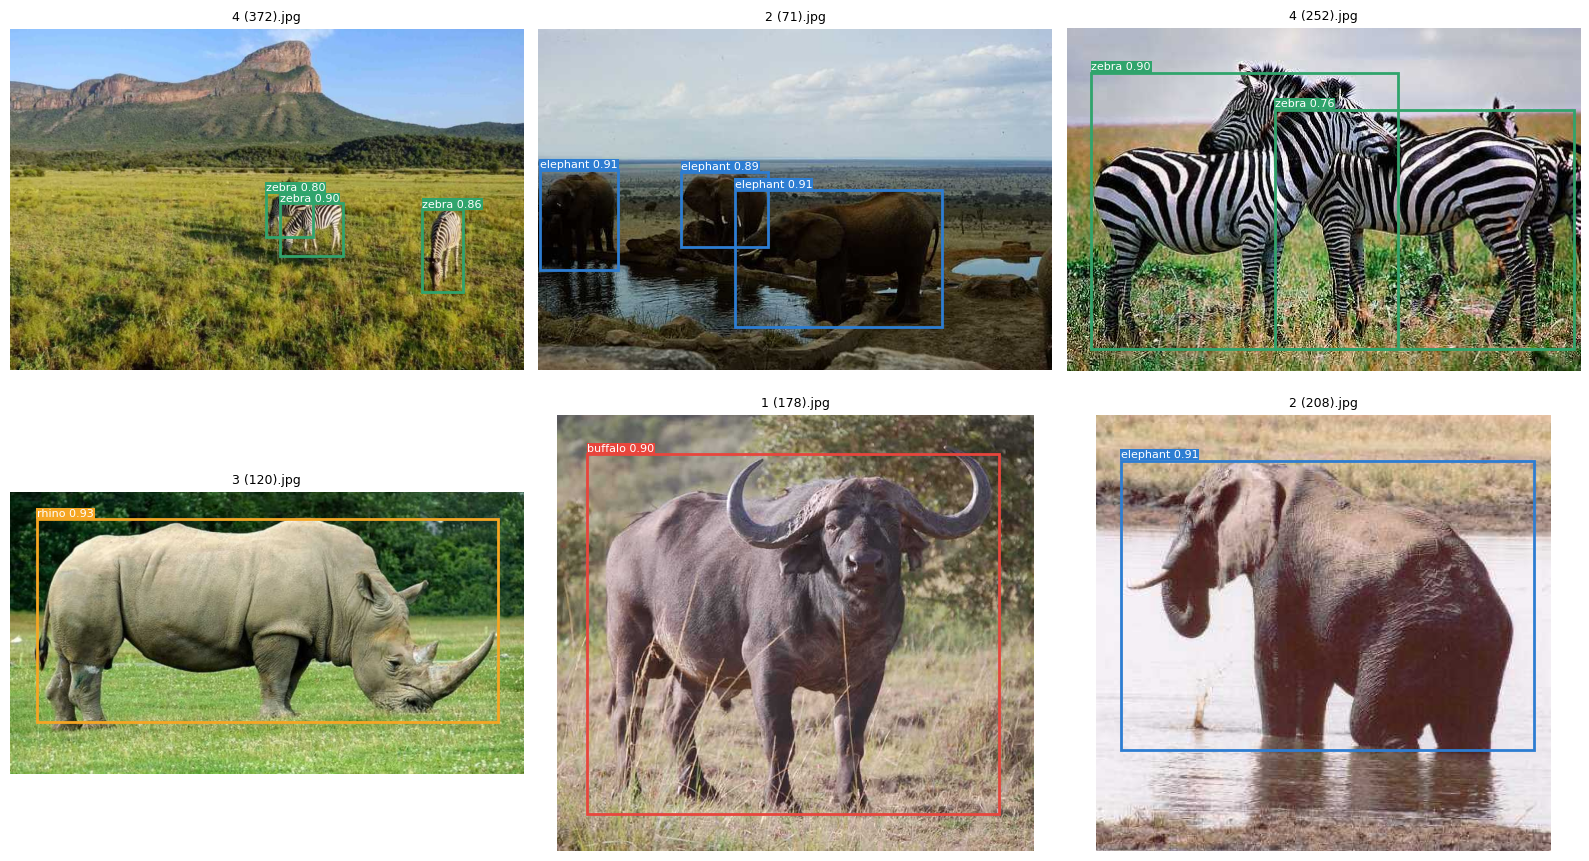

In [35]:
final_model = YOLO(FINAL_WEIGHTS)
random.seed(SEED)
test_photos = random.sample(keep["test"], 6)
results = final_model.predict(test_photos, imgsz=IMGSZ, conf=SHOW_CONF, verbose=False)

all_conf = []
conf_by_class = {c: [] for c in CLASSES}
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, res in zip(axes.ravel(), results):
    ax.imshow(Image.open(res.path)); ax.axis("off")
    for box in res.boxes:
        k = int(box.cls)
        conf = float(box.conf)
        all_conf.append(conf)
        conf_by_class[CLASSES[k]].append(conf)
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                       fill=False, color=COLORS[k], lw=2))
        ax.text(x1, y1 - 3, CLASSES[k] + " " + f"{conf:.2f}", fontsize=8, color="white",
                bbox=dict(facecolor=COLORS[k], pad=0.6, edgecolor="none"))
    ax.set_title(os.path.basename(res.path), fontsize=9)
plt.tight_layout()
fig.savefig("results/test_predictions.png", dpi=110, bbox_inches="tight")
plt.show()

**What we got**

In [36]:
print("boxes drawn       :", len(all_conf))
if all_conf:
    print("average confidence:", round(float(np.mean(all_conf)), 2))
    print("lowest            :", round(min(all_conf), 2),
          "  highest:", round(max(all_conf), 2))
print()
shown = {c: conf_by_class[c] for c in CLASSES if conf_by_class[c]}
for c in shown:
    print(f"   {c:10} {len(shown[c]):>3} boxes, average confidence "
          f"{float(np.mean(shown[c])):.2f}")
if len(shown) > 1:
    sure   = max(shown, key=lambda c: float(np.mean(shown[c])))
    unsure = min(shown, key=lambda c: float(np.mean(shown[c])))
    print()
    print("On these photos the model is most sure about", sure,
          "and least sure about", unsure + ".")
print("Confidence is not accuracy: a wrong box can also have a high number.")

boxes drawn       : 11
average confidence: 0.88
lowest            : 0.76   highest: 0.93

   buffalo      1 boxes, average confidence 0.90
   elephant     4 boxes, average confidence 0.90
   rhino        1 boxes, average confidence 0.93
   zebra        5 boxes, average confidence 0.84

On these photos the model is most sure about rhino and least sure about zebra.
Confidence is not accuracy: a wrong box can also have a high number.


## 15. Error analysis

We compare every prediction with the true boxes. A prediction is **correct**
if it has the same class and covers at least 50% of a true box. Then:

* **missed** — a real animal with no prediction,
* **extra** — a prediction that matches no real animal.

In [37]:
def iou(a, b):
    # how much two boxes overlap: common area / total area, from 0 to 1
    x1 = max(a[0], b[0]); y1 = max(a[1], b[1])      # the common rectangle
    x2 = min(a[2], b[2]); y2 = min(a[3], b[3])
    both = max(0, x2 - x1) * max(0, y2 - y1)        # 0 if they do not touch
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    return both / (area_a + area_b - both + 1e-9)   # 1e-9: never divide by 0

def truth_boxes(image_path):
    # the true boxes of one photo, in pixels, as (class, [x1, y1, x2, y2])
    W, H = Image.open(image_path).size
    out = []
    for k, x, y, w, h in boxes[image_path]:
        x, y, w, h = x * W, y * H, w * W, h * H
        out.append((int(k), [x - w / 2, y - h / 2, x + w / 2, y + h / 2]))
    return out

def match(image_path):
    # returns the true boxes, the predictions, and which predictions were correct
    truth = truth_boxes(image_path)
    res = final_model.predict(image_path, imgsz=IMGSZ, conf=SHOW_CONF, verbose=False)[0]
    pred = [(int(b.cls), b.xyxy[0].tolist()) for b in res.boxes]
    used = set()                            # predictions already matched
    missed_here = collections.Counter()
    for k, true_box in truth:
        hit = False
        for i in range(len(pred)):
            # same class, enough overlap, and not used by another true box
            if i not in used and pred[i][0] == k and iou(true_box, pred[i][1]) >= 0.5:
                used.add(i)
                hit = True
                break                       # one prediction per true box
        if not hit:
            missed_here[CLASSES[k]] += 1
    return truth, pred, used, missed_here

missed = collections.Counter()
extra  = collections.Counter()
truth_count = collections.Counter()
report = {}        # photo -> (missed, extra, missed per class)

for p in keep["test"]:
    truth, pred, used, missed_here = match(p)
    for k, _ in truth:
        truth_count[CLASSES[k]] += 1
    missed += missed_here
    extra_here = 0
    for i in range(len(pred)):
        if i not in used:
            extra[CLASSES[pred[i][0]]] += 1
            extra_here += 1
    report[p] = (sum(missed_here.values()), extra_here, missed_here)

print(f"{'class':10}{'real':>7}{'missed':>9}{'extra':>8}{'recall':>9}")
for c in CLASSES:
    print(f"{c:10}{truth_count[c]:>7}{missed[c]:>9}{extra[c]:>8}"
          f"{1 - missed[c] / truth_count[c]:>9.2f}")

class        real   missed   extra   recall
buffalo        66        3       4     0.95
elephant       99        4       9     0.96
rhino          74        2       2     0.97
zebra         134        7      14     0.95


**What we got**

In [38]:
hardest  = min(CLASSES, key=lambda c: 1 - missed[c] / truth_count[c])
noisiest = max(CLASSES, key=lambda c: extra[c])
clean = sum(1 for p in report if report[p][0] == 0 and report[p][1] == 0)

print("Photos with no error at all:", clean, "of", len(report))
print("Worst class:", hardest, "-", missed[hardest], "of",
      truth_count[hardest], "animals missed.")
print("Most extra boxes:", noisiest, "-", extra[noisiest], "boxes.")
print("Missing boxes and extra boxes are different problems,")
print("so the next part checks where the extra boxes are.")

Photos with no error at all: 187 of 225
Worst class: zebra - 7 of 134 animals missed.
Most extra boxes: zebra - 14 boxes.
Missing boxes and extra boxes are different problems,
so the next part checks where the extra boxes are.


## 16. Why are there extra boxes?

An extra box can mean different things, and each one needs a different fix.
We check **where** every extra box landed:

* on an animal that already has a box → the model drew it twice,
* on an animal of another class → it confused two animals,
* on a place with no box at all → it saw an animal that is not there.

In [39]:
reason = collections.Counter()
confusion = collections.Counter()        # (true class -> predicted class)

for p in keep["test"]:
    truth, pred, used, _ = match(p)
    for i in range(len(pred)):
        if i in used:                    # this one is correct, skip it
            continue
        k, box = pred[i]
        # best overlap with a true box of the same class, and of another class
        same  = max([iou(tb, box) for tk, tb in truth if tk == k], default=0.0)
        other = [(iou(tb, box), tk) for tk, tb in truth if tk != k]
        best_other = max(other, default=(0.0, None))

        if best_other[0] >= 0.5:
            why = "an animal of another class"
            confusion[(CLASSES[best_other[1]], CLASSES[k])] += 1
        elif same >= 0.3:
            why = "the same animal drawn twice"      # NMS kept two boxes
        elif same < 0.1 and best_other[0] < 0.1:
            why = "nothing is there"                 # empty background
        else:
            why = "box in the wrong place"
        reason[(CLASSES[k], why)] += 1

by_reason = collections.Counter()
for (c, why), n in reason.items():
    by_reason[why] += n

total_extra = sum(by_reason.values()) or 1
print("All extra boxes:", total_extra)
for why, n in by_reason.most_common():
    print(f"   {n:>5}  ({n / total_extra * 100:4.1f}%)  {why}")

if confusion:
    print()
    print("Which animals are confused (true -> predicted):")
    for (a, b), n in confusion.most_common(5):
        print(f"   {n:>4}  {a} called {b}")

All extra boxes: 29
      11  (37.9%)  nothing is there
       8  (27.6%)  the same animal drawn twice
       7  (24.1%)  box in the wrong place
       3  (10.3%)  an animal of another class

Which animals are confused (true -> predicted):
      1  buffalo called rhino
      1  rhino called elephant
      1  rhino called buffalo


**What we got**

In [40]:
twice   = by_reason["the same animal drawn twice"]
nothing = by_reason["nothing is there"]
wrong   = by_reason["an animal of another class"]

print("Of all extra boxes:")
print("  ", round(twice / total_extra * 100), "% are the same animal twice,")
print("  ", round(wrong / total_extra * 100), "% are a confusion between two animals,")
print("  ", round(nothing / total_extra * 100), "% are on empty background.")
print()
if twice >= max(nothing, wrong):
    print("The main problem is double boxes on one animal.")
    print("That happens when an animal is large and NMS keeps two boxes.")
    print("A higher IoU threshold in NMS would remove most of them.")
elif wrong >= nothing:
    print("The main problem is confusion between two classes.")
    print("The model sees the animal but gives it the wrong name,")
    print("so the fix is more examples of the two classes it mixes, not more boxes.")
else:
    print("The main problem is boxes on empty background.")
    print("The model sees an animal where there is none, usually in grass or rocks.")
    print("A higher confidence threshold would remove most of these.")

Of all extra boxes:
   28 % are the same animal twice,
   10 % are a confusion between two animals,
   38 % are on empty background.

The main problem is boxes on empty background.
The model sees an animal where there is none, usually in grass or rocks.
A higher confidence threshold would remove most of these.


## 17. Three failure cases

We do not take the three worst photos, because they would all show the same
problem. We take one photo for each type of error.

In [41]:
def worst_by(fn):
    return max(report, key=fn)

case1 = worst_by(lambda p: report[p][0])                 # most missed animals
case2 = worst_by(lambda p: report[p][1])                 # most extra boxes
# a photo with both kinds at once: an animal replaced by a wrong box
case3 = worst_by(lambda p: min(report[p][0], report[p][1]))

cases = [("Case 1: missed animals", case1),
         ("Case 2: extra boxes", case2),
         ("Case 3: missed and extra together", case3)]

for title, p in cases:
    n_missed, n_extra, by_class = report[p]
    print(title)
    print("  ", os.path.basename(p), "- missed", n_missed, dict(by_class),
          "- extra", n_extra)

Case 1: missed animals
   1 (196).jpg - missed 1 {'buffalo': 1} - extra 0
Case 2: extra boxes
   2 (115).jpg - missed 0 {} - extra 2
Case 3: missed and extra together
   1 (373).jpg - missed 1 {'buffalo': 1} - extra 1


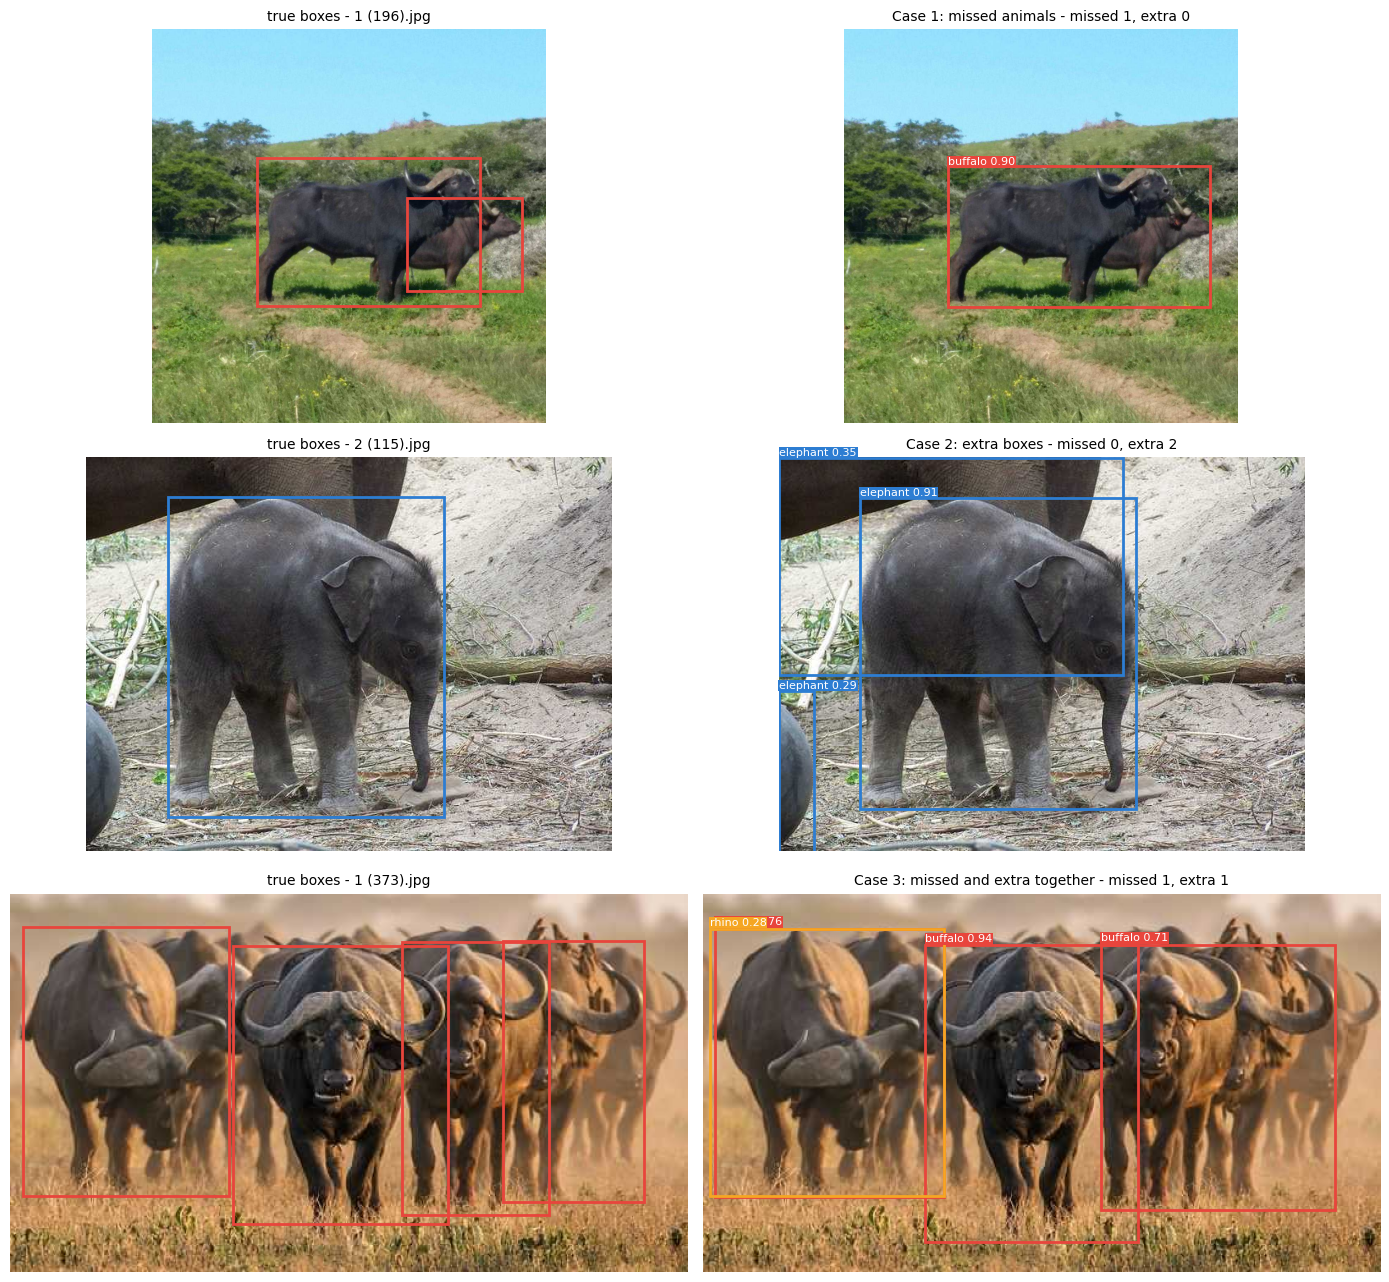

In [42]:
fig, axes = plt.subplots(3, 2, figsize=(14, 13))
for row in range(3):
    title, p = cases[row]
    draw_boxes(axes[row, 0], p, title=False)
    axes[row, 0].set_title("true boxes - " + os.path.basename(p), fontsize=10)

    res = final_model.predict(p, imgsz=IMGSZ, conf=SHOW_CONF, verbose=False)[0]
    axes[row, 1].imshow(Image.open(p)); axes[row, 1].axis("off")
    for box in res.boxes:
        k = int(box.cls)
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        axes[row, 1].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                                 fill=False, color=COLORS[k], lw=2))
        axes[row, 1].text(x1, y1 - 3, CLASSES[k] + " " + f"{float(box.conf):.2f}",
                          fontsize=8, color="white",
                          bbox=dict(facecolor=COLORS[k], pad=0.6, edgecolor="none"))
    n_missed, n_extra, _ = report[p]
    axes[row, 1].set_title(title + " - missed " + str(n_missed) +
                           ", extra " + str(n_extra), fontsize=10)
plt.tight_layout()
fig.savefig("results/failure_cases.png", dpi=110, bbox_inches="tight")
plt.show()

**Why these three things happen**

**Case 1 — missed animals.** The photos where the model misses something are
usually the crowded ones: a herd, where the animals stand behind each other.
Part 4 showed that most photos have one animal, so the model almost never
trains on a herd, and it learns "one big animal per photo".

**Case 2 — extra boxes.** Part 16 gives the numbers. Two different things hide
here: the same animal boxed twice, which is an NMS problem and is easy to fix
with a threshold, and a box on empty grass, which is a real mistake of the
model.

**Case 3 — missed and extra in the same photo.** This is usually one error, not
two: the model found the animal but called it by the wrong name. The true box
counts as missed and the prediction counts as extra. The confusion table in
part 16 shows which pair of animals this happens with.

**One next step.** The cheapest improvement is not a bigger model: it is to
check the predictions on the crowded photos again with a higher NMS IoU and a
higher confidence threshold, and see how much of the error list disappears.
Only what is left after that is a real model problem, and then the answer would
be more training photos with several animals in one picture.

## 18. Summary and files to keep

In [43]:
summary = {
    "dataset": "African Wildlife (Ultralytics), AGPL-3.0, 1504 photos, 4 classes",
    "split_original": {s: len(images[s]) for s in SPLITS},
    "split_used": {s: len(keep[s]) for s in SPLITS},
    "removed_duplicates": len(drop),
    "near_duplicate_pairs": len(pairs),
    "near_duplicate_pairs_crossing_splits": len(crossing),
    "framework": "ultralytics " + ultralytics.__version__ + ", torch " + torch.__version__,
    "model": MODEL, "epochs": EPOCHS, "batch": BATCH, "imgsz": IMGSZ,
    "lr0": LR0, "optimizer": OPT, "seed": SEED,
    "eval": {"conf": CONF, "iou": IOU, "picture_conf": SHOW_CONF},
    "run1_mosaic_on":  {"mosaic": MOSAIC_1, "minutes": round(time1 / 60, 1),
                        "val": {k: round(float(v), 4) for k, v in val1.items()}},
    "run2_mosaic_off": {"mosaic": MOSAIC_2, "minutes": round(time2 / 60, 1),
                        "val": {k: round(float(v), 4) for k, v in val2.items()}},
    "chosen": FINAL_NAME,
    "test": {k: round(float(v), 4) for k, v in test.items()},
    "errors": {"missed": dict(missed), "extra": dict(extra),
               "extra_reasons": dict(by_reason),
               "confused_pairs": {a + " -> " + b: n for (a, b), n in confusion.items()}},
}

json.dump(summary, open("results/summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))

{
  "dataset": "African Wildlife (Ultralytics), AGPL-3.0, 1504 photos, 4 classes",
  "split_original": {
    "train": 1052,
    "val": 225,
    "test": 227
  },
  "split_used": {
    "train": 1018,
    "val": 225,
    "test": 225
  },
  "removed_duplicates": 36,
  "near_duplicate_pairs": 75,
  "near_duplicate_pairs_crossing_splits": 37,
  "framework": "ultralytics 8.4.215, torch 2.14.1+cu130",
  "model": "yolo11n.pt",
  "epochs": 50,
  "batch": 16,
  "imgsz": 640,
  "lr0": 0.01,
  "optimizer": "SGD",
  "seed": 0,
  "eval": {
    "conf": 0.001,
    "iou": 0.6,
    "picture_conf": 0.25
  },
  "run1_mosaic_on": {
    "mosaic": 1.0,
    "minutes": 14.7,
    "val": {
      "precision": 0.9433,
      "recall": 0.891,
      "mAP50": 0.9536,
      "mAP50-95": 0.7941,
      "buffalo precision": 0.9434,
      "buffalo recall": 0.8539,
      "buffalo mAP50": 0.965,
      "elephant precision": 0.9078,
      "elephant recall": 0.8653,
      "elephant mAP50": 0.9326,
      "rhino precision": 0.9602,

In [44]:
# runs/ is not on GitHub, so copy the two checkpoints out of it
shutil.copy(BEST1, "results/best_run1_mosaic_on.pt")
shutil.copy(BEST2, "results/best_run2_mosaic_off.pt")
shutil.copy("data.yaml", "results/data.yaml")
shutil.make_archive("wildlife_evidence", "zip", "results")    # one file to download

for folder, subfolders, files in os.walk("results"):
    for f in sorted(files):
        full = os.path.join(folder, f)
        print(f"{full:48}{os.path.getsize(full) / 1024:>8.0f} KB")
print()
print("archive:", round(os.path.getsize("wildlife_evidence.zip") / 1e6, 1), "MB")

results/best_run1_mosaic_on.pt                      5360 KB
results/best_run2_mosaic_off.pt                     5360 KB
results/data.yaml                                      0 KB
results/failure_cases.png                           1409 KB
results/ground_truth_examples.png                   2213 KB
results/summary.json                                   3 KB
results/test_predictions.png                        2260 KB
results/run2_mosaic_off/BoxPR_curve.png              122 KB
results/run2_mosaic_off/args.yaml                      2 KB
results/run2_mosaic_off/confusion_matrix_normalized.png     143 KB
results/run2_mosaic_off/results.csv                    6 KB
results/run2_mosaic_off/results.png                  333 KB
results/run1_mosaic_on/BoxPR_curve.png               120 KB
results/run1_mosaic_on/args.yaml                       2 KB
results/run1_mosaic_on/confusion_matrix_normalized.png     143 KB
results/run1_mosaic_on/results.csv                     6 KB
results/run1_mosaic_on/resu

**What to do with these files**

1. Commit everything in `results/` **except** the two `.pt` files.
2. Upload `results/best_<chosen run>.pt` to Google Drive, make the link public,
   and put the link in the README.
3. Copy the numbers from `summary.json` into the README tables.

In [45]:
from google.colab import files    # skip this cell if you are not in Colab
files.download("wildlife_evidence.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>